In [22]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


In [23]:
%pip install seaborn 

In [24]:
import seaborn as sns


In [29]:
import pandas as pd
df=pd.read_csv('Hotel Bookings.csv')

In [30]:
df.shape

(119390, 32)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [32]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [33]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [34]:
df.duplicated().sum()

np.int64(31994)

In [35]:
df=df.drop_duplicates()
df.shape

(87396, 32)

In [36]:
df["company"]=df["company"].fillna(0)
df["country"]=df["country"].fillna(0)
df["children"]=df["children"].fillna(0)
df["agent"]=df["agent"].fillna(0)

In [37]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [38]:
# 1.Which type of hotels is most preferred by the guests?
df["hotel"].value_counts()

hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

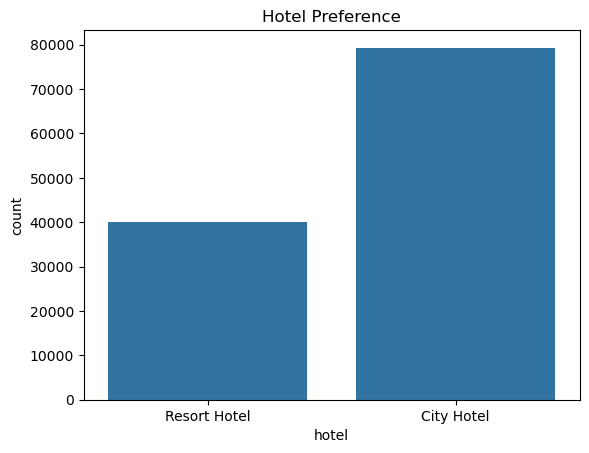

In [7]:
sns.countplot(data=df, x='hotel')
plt.title("Hotel Preference")
plt.show()

In [8]:
# 2.What is the percentage of hotel booking cancellations?
calculate_percent=df["is_canceled"].mean()*100
print(calculate_percent)

37.041628277075134


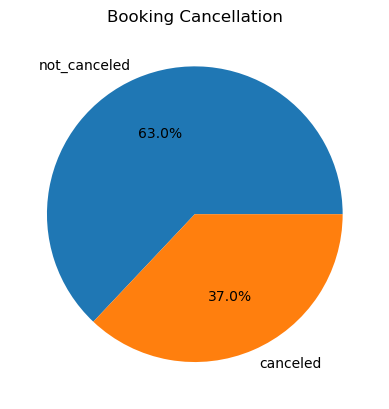

In [9]:
cancel_counts=df["is_canceled"].value_counts()
cancel_counts
plt.pie(cancel_counts,labels=["not_canceled","canceled"],autopct="%1.1f%%")
plt.title("Booking Cancellation")
plt.show()

In [10]:
#3. Which type of meal is most preferred by the guests?
df["meal"].value_counts()

meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

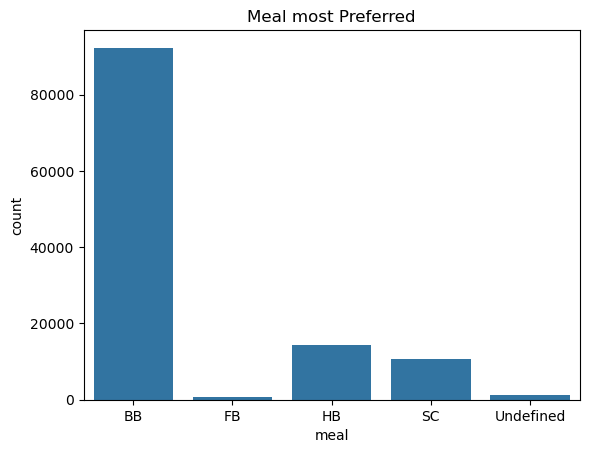

In [9]:
sns.countplot(data=df,x='meal')
plt.title("Meal most Preferred")
plt.show()

In [12]:
#4. Which year has the most bookings?
df["arrival_date_year"].value_counts().sort_index()

arrival_date_year
2015    21996
2016    56707
2017    40687
Name: count, dtype: int64

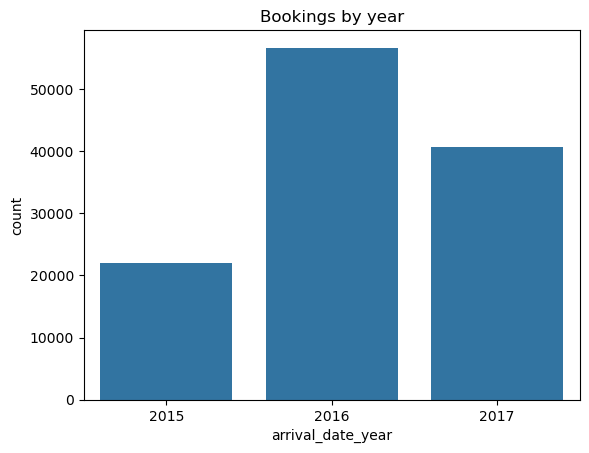

In [11]:
sns.countplot(data=df,x='arrival_date_year')
plt.title("Bookings by year")
plt.show()

In [14]:
# 5.Which month has the most bookings in each hotel type?
df["arrival_date_month"].value_counts().sort_index()

arrival_date_month
April        11089
August       13877
December      6780
February      8068
January       5929
July         12661
June         10939
March         9794
May          11791
November      6794
October      11160
September    10508
Name: count, dtype: int64

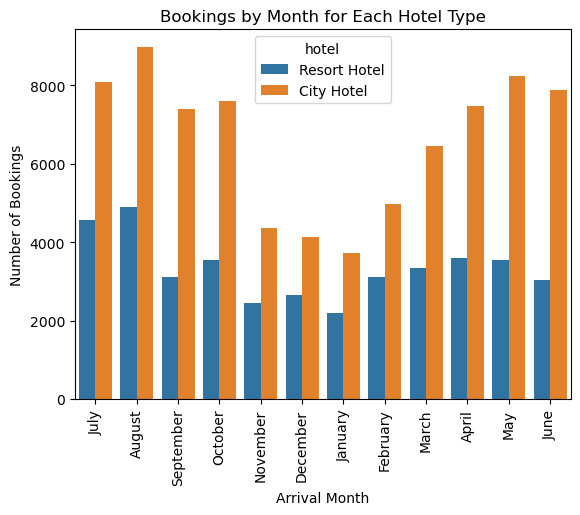

In [11]:
sns.countplot(x="arrival_date_month", hue="hotel", data=df)
plt.xlabel("Arrival Month")
plt.xticks(rotation=90)
plt.ylabel("Number of Bookings")
plt.title("Bookings by Month for Each Hotel Type")
plt.show()

In [12]:
#6. From which country most guests come?
df["country"].value_counts()

country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
       ...  
DJI        1
BWA        1
HND        1
VGB        1
NAM        1
Name: count, Length: 177, dtype: int64

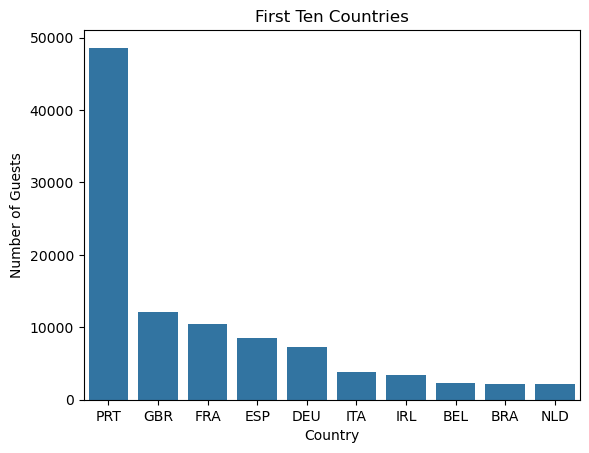

In [13]:
first_ten= df['country'].value_counts().head(10)
sns.barplot(x=first_ten.index, y=first_ten.values)
plt.xlabel("Country")
plt.ylabel("Number of Guests")
plt.title("First Ten Countries")
plt.show()

In [14]:
#7.	Which distribution channel is most used in booking?
df["distribution_channel"].value_counts()

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64

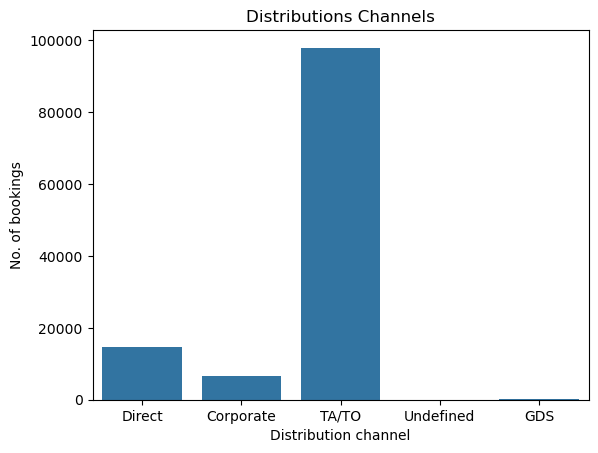

In [15]:
sns.countplot(data=df,x="distribution_channel")
plt.xlabel("Distribution channel")
plt.ylabel("No. of bookings")
plt.title("Distributions Channels")
plt.show()

In [16]:
#8.	Which room type is most preferred  by guests?
df["reserved_room_type"].value_counts()

reserved_room_type
A    85994
D    19201
E     6535
F     2897
G     2094
B     1118
C      932
H      601
P       12
L        6
Name: count, dtype: int64

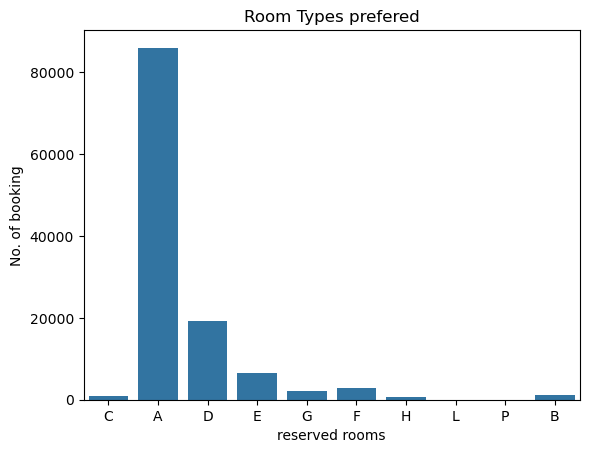

In [17]:
sns.countplot(data=df,x="reserved_room_type")
plt.xlabel("reserved rooms")
plt.ylabel("No. of booking")
plt.title("Room Types prefered")
plt.show()

In [18]:
#9.	Which room type is most assigned?
df["assigned_room_type"].value_counts()

assigned_room_type
A    74053
D    25322
E     7806
F     3751
G     2553
C     2375
B     2163
H      712
I      363
K      279
P       12
L        1
Name: count, dtype: int64

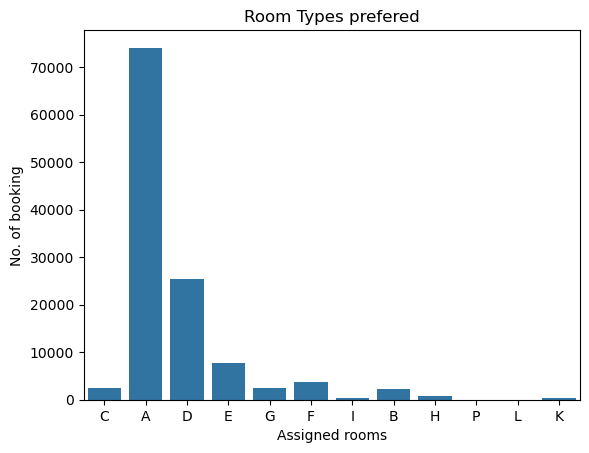

In [19]:
sns.countplot(data=df,x="assigned_room_type")
plt.xlabel("Assigned rooms")
plt.ylabel("No. of booking")
plt.title("Room Types prefered")
plt.show()

In [21]:
#10.	Top 5 agents in terms of most bookings?
df["agent"].value_counts().head(5)


agent
9.0      31961
240.0    13922
1.0       7191
14.0      3640
7.0       3539
Name: count, dtype: int64

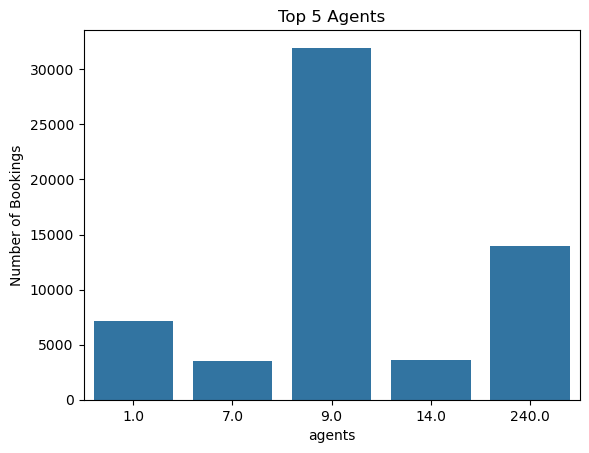

In [22]:
first_five= df['agent'].value_counts().head(5)
sns.barplot(x=first_five.index, y=first_five.values)
plt.xlabel("agents")
plt.ylabel("Number of Bookings")
plt.title("Top 5 Agents")
plt.show()

In [23]:
#11.	What is the percentage of repeated guests?
repeated_guest=df["is_repeated_guest"].mean()*100
print(repeated_guest)

3.191222045397437


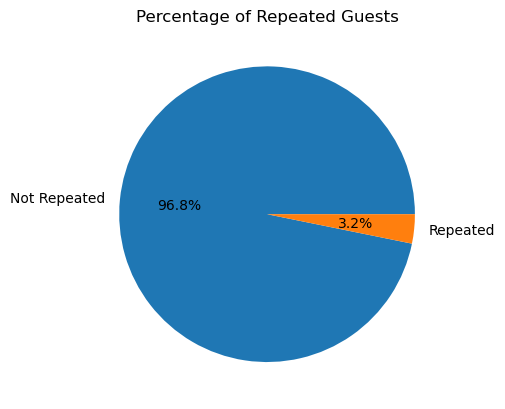

In [24]:
repeated_guest=df["is_repeated_guest"].value_counts()
plt.pie(repeated_guest,labels=['Not Repeated', 'Repeated'],autopct='%1.1f%%')
plt.title("Percentage of Repeated Guests")
plt.show()

In [25]:
#12. Which customer type has the most booking?
df['customer_type'].value_counts()

customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64

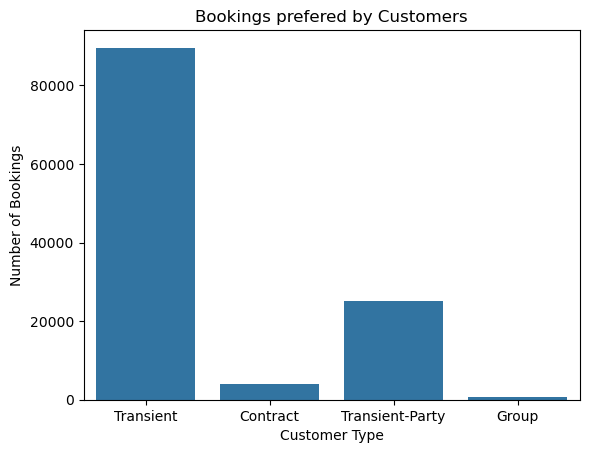

In [28]:
sns.countplot(x="customer_type", data=df)
plt.xlabel("Customer Type")
plt.ylabel("Number of Bookings")
plt.title("Bookings prefered by Customers")
plt.show()

In [30]:
#13.	Which Market Segment has the most booking?
df["market_segment"].value_counts()

market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

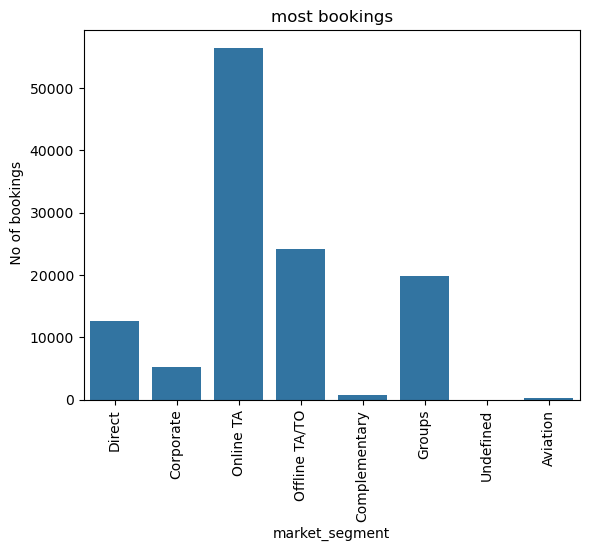

In [33]:
sns.countplot(data=df,x="market_segment")
plt.title("most bookings")
plt.xlabel("market_segment")
plt.ylabel(" No of bookings")
plt.xticks(rotation=90)
plt.show()

In [34]:
#14.Which deposit type is most preferred ?
df["deposit_type"].value_counts()

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

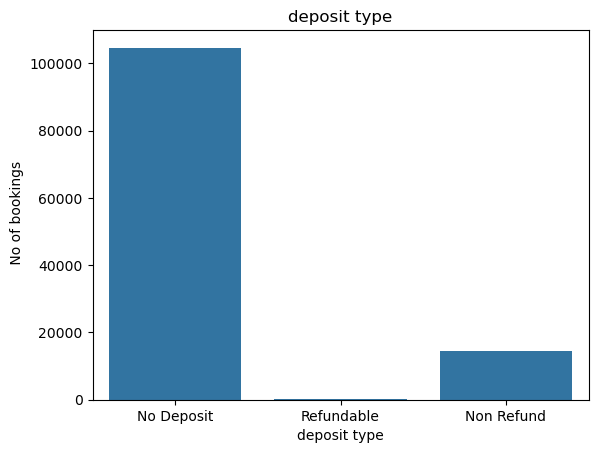

In [36]:
sns.countplot(data=df,x="deposit_type")
plt.title("deposit type")
plt.xlabel("deposit type")
plt.ylabel(" No of bookings")
plt.show()

In [37]:
#15.How long people stay in the hotel?
df['total_stay']=df['stays_in_weekend_nights']+df['stays_in_week_nights']
df['total_stay'].value_counts()

totalstay
2     27643
3     27076
1     21020
4     17383
7      8655
5      7784
6      3857
8      1161
10     1139
14      916
9       841
0       715
11      396
12      223
13      142
15       75
21       71
16       40
25       37
18       35
28       35
19       22
17       20
29       14
20       14
22       14
30       13
23        8
24        6
26        6
27        5
35        5
42        4
33        3
56        2
34        1
57        1
49        1
48        1
69        1
38        1
45        1
60        1
46        1
43        1
Name: count, dtype: int64

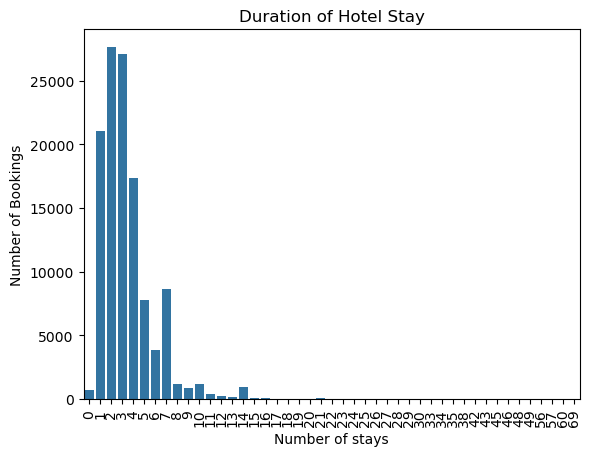

In [40]:
stay_counts = df['totalstay'].value_counts()

sns.barplot(x=stay_counts.index, y=stay_counts.values)
plt.xlabel("Number of stays")
plt.ylabel("Number of Bookings")
plt.title("Duration of Hotel Stay")
plt.xticks(rotation=90)
plt.show()


In [44]:
#16.Which hotel makes most revenue?
df["total_stay_nights"]=df['stays_in_weekend_nights']+df['stays_in_week_nights']
print(df["total_stay_nights"])

0         0
1         0
2         1
3         1
4         2
         ..
119385    7
119386    7
119387    7
119388    7
119389    9
Name: total_stay_nights, Length: 87396, dtype: int64


In [45]:
df["revenue"]=df["adr"]*df["total_stay_nights"]

In [47]:
df.groupby("hotel")["revenue"].sum().sort_values(ascending=False)

hotel
City Hotel      18774101.54
Resort Hotel    15686837.77
Name: revenue, dtype: float64

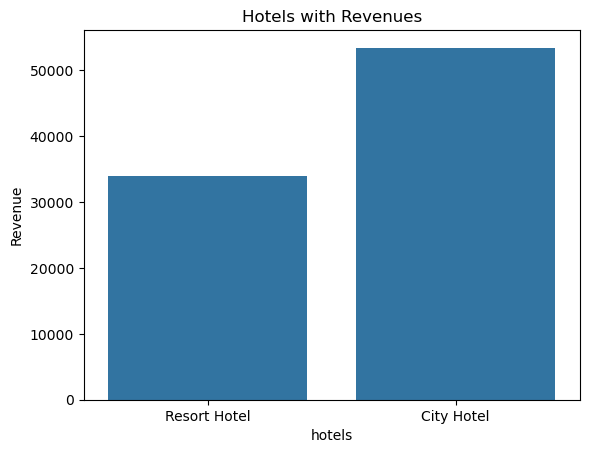

In [49]:
sns.countplot(data=df,x="hotel")
plt.xlabel("hotels")
plt.ylabel("Revenue")
plt.title("Hotels with Revenues")
plt.show()


In [50]:
#17.Which hotel has the long waiting time ?
df.groupby("hotel")["days_in_waiting_list"].mean()

hotel
City Hotel      1.020233
Resort Hotel    0.323834
Name: days_in_waiting_list, dtype: float64

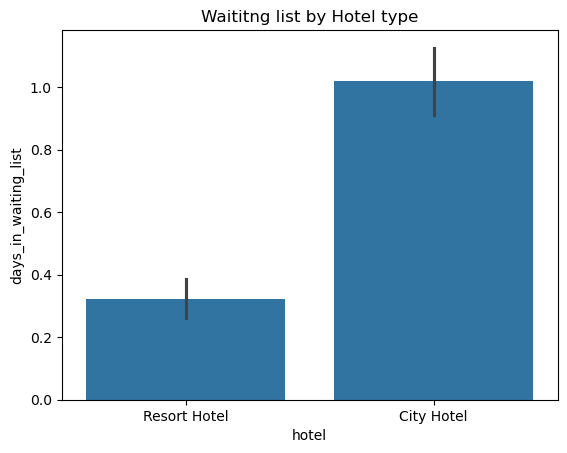

In [55]:
sns.barplot(data=df,x="hotel",y="days_in_waiting_list")
plt.title("Waititng list by Hotel type")
plt.show()

In [56]:
#18.Hotel with most reapeted guests?
df.groupby("hotel")["is_repeated_guest"].sum() 

hotel
City Hotel      1708
Resort Hotel    1707
Name: is_repeated_guest, dtype: int64

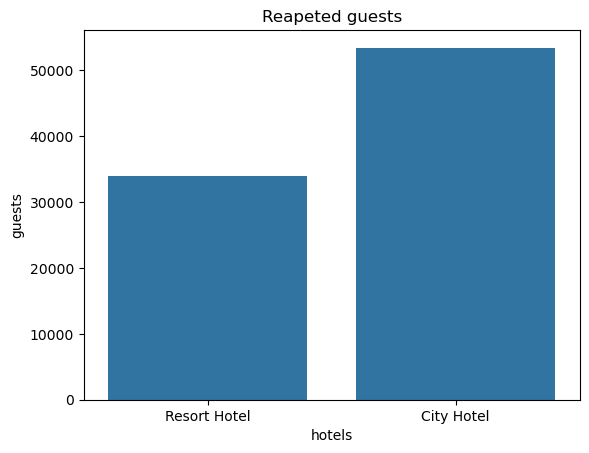

In [57]:
sns.countplot(data=df,x="hotel")
plt.xlabel("hotels")
plt.ylabel("guests")
plt.title("Reapeted guests")
plt.show()

In [66]:
#19.What is the adr across different months ?
month_adr=df.groupby(["arrival_date_month","hotel"])["adr"].mean()
print(month_adr)

arrival_date_month  hotel       
April               City Hotel      117.156250
                    Resort Hotel     79.283805
August              City Hotel      124.901601
                    Resort Hotel    187.566659
December            City Hotel       92.717339
                    Resort Hotel     65.409093
February            City Hotel       88.945304
                    Resort Hotel     54.081107
January             City Hotel       85.092612
                    Resort Hotel     49.131584
July                City Hotel      120.055385
                    Resort Hotel    156.166914
June                City Hotel      123.836342
                    Resort Hotel    112.340141
March               City Hotel       94.763375
                    Resort Hotel     57.569213
May                 City Hotel      127.851240
                    Resort Hotel     80.551101
November            City Hotel       89.454120
                    Resort Hotel     48.823434
October             City Ho

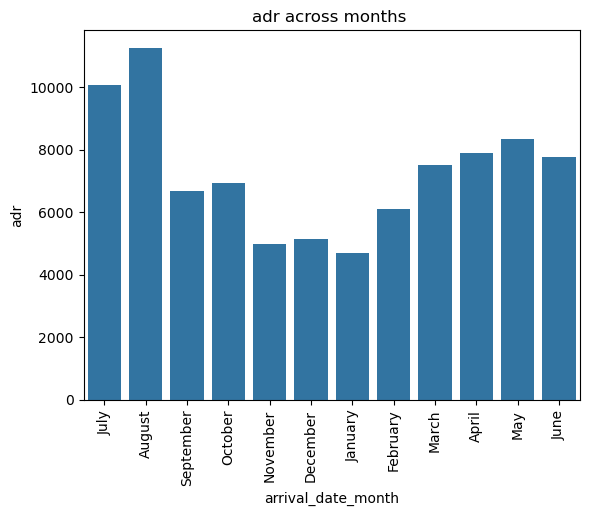

In [68]:
sns.countplot(data=df,x="arrival_date_month")
plt.xlabel("arrival_date_month")
plt.ylabel("adr")
plt.title("adr across months ")
plt.xticks(rotation=90)
plt.show()

In [70]:
#20.Which distribution channel has the highest adr?
df.groupby("distribution_channel")["adr"].mean().sort_values(ascending=False)

distribution_channel
GDS          120.317845
Direct       109.133604
TA/TO        108.559116
Corporate     68.515682
Undefined     46.240000
Name: adr, dtype: float64

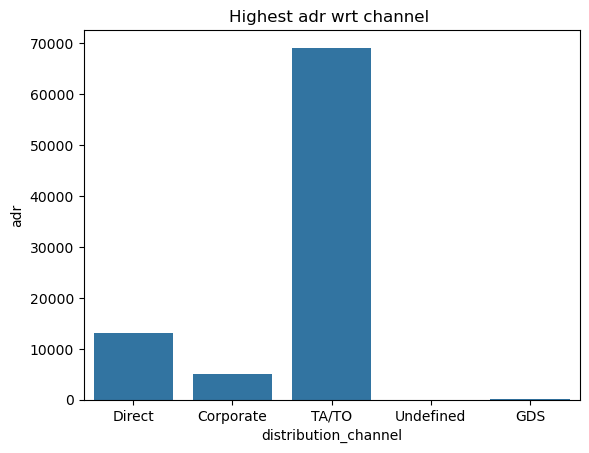

In [71]:
sns.countplot(data=df,x="distribution_channel")
plt.xlabel("distribution_channel")
plt.ylabel("adr")
plt.title("Highest adr wrt channel ")
plt.show()

#21.what do you suggest the client to achieve business objective?
Recommendations :

1. Reduce Cancellations as this will create bad images of hotels .
2. Make repeated bookings and waiting list too because if any cancellations occurs then it will be filled .
3. Attract more customers by making customer satisfication.
4. Improve marketing by focusing on market segments abd distribution channels as this generates more bookings .
5. Increase revenue by giving proper services and by attracting the customers.
6. Reduce waiting times
7. Increase longer stays in hotels.
8. Regularly analyse trends of bookings .
9. Make a proper analysis of bookings and offer discount too acording to season as this will attract more bookings.

#22. Conclusion .

     We performed EDA on "Hotel Bookings" dataset .Firstly we cleaned dataset by checking whether there is null values,duplicates,etc.Then cleaned by       dropping duplicates , dropping null values and aslo filling empty dataset with zeros. For visualization and calculations various libraries were        installed such as NumPy, Pandas,Matplotlib,Seaborn .We further analysed booking trends,cancellations,customer preferences,revenues and adr. Due        to this we get to know customers behaviour and hotel performance. This overall analysis can help the client to upgrade the business and make           proper decisions.  